# Fix It at Work – Exploratory Data Analysis (EDA)

## 1. Business Understanding & Requirements

### 1.1 Business Background

Fix It at Work is a workplace issue reporting and management
system designed to help employees report problems and enable
support teams to manage and resolve them efficiently.

The system aims to improve transparency, accountability,
response times, and service quality through a structured
ticket management process.

This data analytics project focuses on analysing workplace
issue reports to identify operational patterns, evaluate
service performance, monitor Service Level Agreement (SLA)
compliance, and support data-driven decision-making.

The analysis uses a synthetic dataset containing 300
workplace issue reports, processed through a Python ETL
pipeline.

The project will combine:

- Exploratory Data Analysis (EDA)
- Statistical Analysis and Hypothesis Testing
- Data Modelling using a Star Schema
- Power BI Dashboard Development
- Exploratory Machine Learning for SLA Breach Prediction

The findings will support the development of management
dashboards and help identify opportunities for improving
workplace issue resolution.

### 1.2 Business Questions & KPIs

#### Business Questions

The analysis aims to answer five key business questions:

1. How many workplace issues are reported, and what are their current statuses?
2. Which issue categories and priorities occur most frequently?
3. How efficiently are tickets resolved, and how often are SLA targets breached?
4. How does ticket volume and resolution performance vary across support teams?
5. Can Machine Learning predict the risk of a resolution SLA breach?

#### Key Performance Indicators (KPIs)

The following KPIs will be used to monitor operational performance:

| KPI | Description |
|---|---|
| Total Tickets | Total number of reported workplace issues |
| Open Tickets | Number of tickets not yet resolved or closed |
| Average Response Time | Average time taken to provide the first response |
| Average Resolution Time | Average time taken to resolve completed tickets |
| Response SLA Compliance (%) | Percentage of eligible tickets meeting response SLA targets |
| Resolution SLA Compliance (%) | Percentage of eligible tickets meeting resolution SLA targets |
| SLA Breach Rate (%) | Percentage of eligible tickets breaching SLA targets |
| Tickets by Priority | Distribution of tickets across priority levels |
| Tickets by Category | Distribution of reported issue categories |
| Team Performance | Ticket workload and resolution performance by assigned team |

#### Expected Deliverables

- Exploratory Data Analysis using Python.
- SLA and team performance analysis.
- Star Schema data model for Power BI.
- Interactive management dashboard integrated into the Django website.
- Experimental Machine Learning model for SLA breach prediction.
- Key business insights and recommendations.

**Data Limitation:** The analysis uses synthetic data.
Machine Learning predictions will be presented as experimental
until validated using real operational data.

## 2. Data Understanding & Exploratory Data Analysis

### 2.1 Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
print("Current working directory:")
print(Path.cwd())

Current working directory:
c:\Users\lap-mohammadnejhad\.vscode\fix-it-at-work\data-analytics\EDA


### 2.2 Load Cleaned Dataset

Load the cleaned dataset generated by the ETL pipeline for exploratory data analysis.

In [4]:
# Define the path to the cleaned dataset
data_path = Path.cwd().parent / "Data" / "Processed" / "cleaned_tickets.csv"

# Load the dataset
df = pd.read_csv(data_path)

# Display dataset dimensions
print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Preview the first five records
display(df.head())

Dataset loaded successfully!
Rows: 300
Columns: 40


,Ticket Ref,User ID,Reporter Name,Department,Contact Email,Contact Phone,Reporting Channel,Title,Description,Category,...,Resolution SLA,Times Reopened,Root Cause,Technician Notes,Cost (£),Satisfaction (1-5),Satisfaction Comments,Last Updated,Response Target (hrs),Resolution Target (hrs)
0,TKT-2025-0001,EMP054,Charlotte Bell,HR,charlotte.bell@examplecouncil.gov.uk,01632 960577,Walk-in,Heating not working,Office heating has stopped working and the roo...,Facilities,...,Met,0,Airlock in radiator circuit,Bled radiators on the circuit and topped up sy...,0.0,5.0,NaN,2025-11-11 12:21:00,4,24.0
1,TKT-2025-0002,EMP008,Daniel Kowalski,Environmental Health,daniel.kowalski@examplecouncil.gov.uk,01632 960806,Phone,Office too cold,Office temperature was below 16°C when staff a...,Facilities,...,Met,0,Seized thermostatic radiator valve,Replaced the TRV and bled the radiator circuit...,80.0,5.0,Really quick response and the engineer explain...,2025-11-17 09:03:00,4,24.0
2,TKT-2025-0003,EMP055,Dominic Edwards,Legal & Democratic Services,dominic.edwards@examplecouncil.gov.uk,01632 960586,Phone,Washroom out of supplies,No soap or paper towels in the staff washroom.,Cleaning & Hygiene,...,Met,0,Missed restock on cleaning round,Restocked and added to the afternoon check list.,0.0,NaN,NaN,2025-11-13 15:28:00,24,120.0
3,TKT-2025-0004,EMP041,Lee Dawson,Waste & Recycling,lee.dawson@examplecouncil.gov.uk,01632 960460,Phone,Refuse vehicle won't start,"Refuse truck won't start this morning, so the ...",Fleet & Vehicles,...,Met,0,Flat battery (cold weather),"Jump-started, then the battery was replaced in...",200.0,5.0,NaN,2025-11-14 13:59:00,1,4.0
4,TKT-2025-0005,EMP037,Rebecca Hall,Environmental Health,rebecca.hall@examplecouncil.gov.uk,01632 960424,Email,No heating on whole floor,None of the radiators on this floor are coming...,Facilities,...,Breached,0,Failed boiler circulation pump,Heating engineer replaced the circulation pump...,900.0,3.0,Got there in the end but it took a while.,2025-11-18 09:36:00,4,24.0


### 2.3 Dataset Overview

This section examines the structure of the cleaned dataset,
including its dimensions, column names, and data types.

Understanding the dataset structure is essential before
performing statistical analysis and visualisations.

In [5]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
for col in df.columns:
    print(col)

# Display dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (300, 40)

Column Names:
Ticket Ref
User ID
Reporter Name
Department
Contact Email
Contact Phone
Reporting Channel
Title
Description
Category
Sub-Category
Priority
Impact
H&S Risk
Location
Building
Asset Tag
Date Reported
Status
Assigned Team
Assigned To
External Contractor
Response Due
First Response
Resolution Due
Date Resolved
Date Closed
Response Time (hrs)
Resolution Time (hrs)
Response SLA
Resolution SLA
Times Reopened
Root Cause
Technician Notes
Cost (£)
Satisfaction (1-5)
Satisfaction Comments
Last Updated
Response Target (hrs)
Resolution Target (hrs)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 40 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Ticket Ref               300 non-null    str    
 1   User ID                  300 non-null    str    
 2   Reporter Name            300 non-null    str    
 3   Department               300

### 2.4 Descriptive Statistics

Data quality checks were completed during the ETL stage.

This section explores the statistical characteristics of
numerical variables to understand their distributions,
central tendencies, and variability.

In [6]:
# Summary statistics for numerical variables
numerical_summary = df.describe()

display(numerical_summary)

,Response Time (hrs),Resolution Time (hrs),Times Reopened,Cost (£),Satisfaction (1-5),Response Target (hrs),Resolution Target (hrs)
count,299.000000,294.000000,300.000000,294.000000,221.000000,300.000000,300.000000
mean,5.862542,51.626531,0.086667,138.608844,3.782805,8.230000,53.960000
std,15.304594,65.191598,0.281816,277.591371,1.155175,7.186277,37.639352
min,0.100000,0.500000,0.000000,0.000000,1.000000,1.000000,4.000000
25%,0.400000,5.725000,0.000000,0.000000,3.000000,4.000000,24.000000
50%,1.200000,26.250000,0.000000,35.000000,4.000000,8.000000,72.000000
75%,3.150000,73.975000,0.000000,155.000000,5.000000,8.000000,72.000000
max,90.500000,387.300000,1.000000,2200.000000,5.000000,24.000000,120.000000


### 2.5 Distribution Analysis

This section examines the distribution of ticket response
and resolution times.

Histograms are used to identify skewness, variability,
and potentially extreme values.

The results will help explain operational performance
and support further statistical analysis.

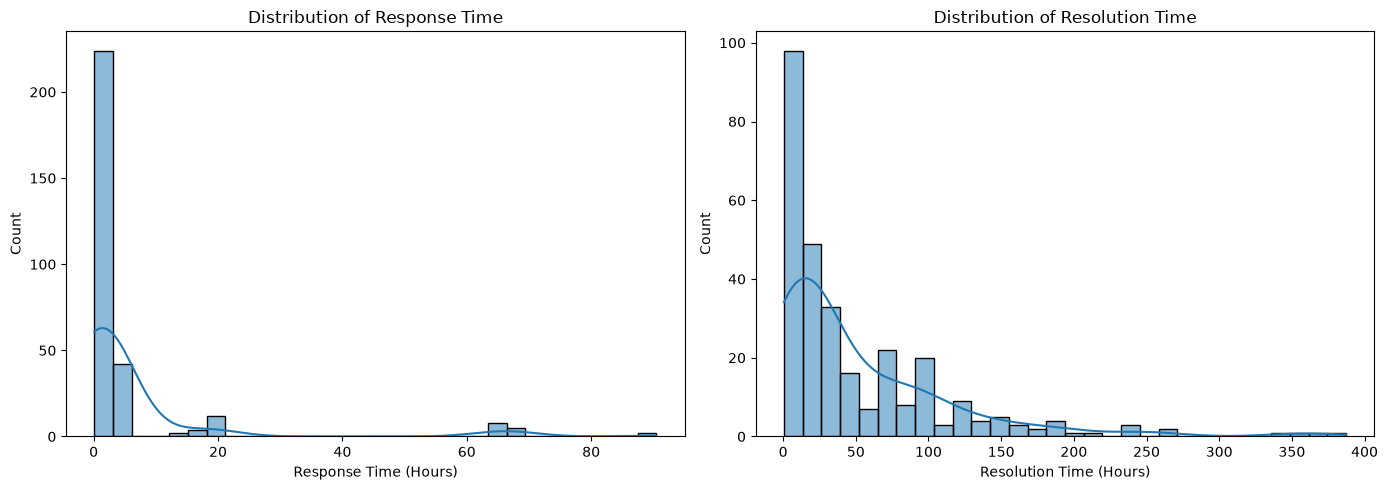

In [7]:
# Distribution of response and resolution times

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="Response Time (hrs)",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Response Time")
axes[0].set_xlabel("Response Time (Hours)")

sns.histplot(
    data=df,
    x="Resolution Time (hrs)",
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of Resolution Time")
axes[1].set_xlabel("Resolution Time (Hours)")

plt.tight_layout()
plt.show()

#### 2.5.1 Key Findings – Time Distribution

The distributions of response and resolution times are
positively skewed, indicating that most tickets are handled
within relatively short periods, while a smaller number
experience substantially longer processing times.

**Response Time:**
- Mean: 5.86 hours
- Median: 1.20 hours
- Maximum: 90.50 hours

**Resolution Time:**
- Mean: 51.63 hours
- Median: 26.25 hours
- Maximum: 387.30 hours

**Business Insight:**

The substantial differences between mean and median values
suggest that unusually long processing times influence
overall averages.

Therefore, median resolution time, percentiles, and SLA
compliance should be considered alongside average
resolution time when evaluating operational performance.

**Analytical Implication:**

Given the right-skewed distributions, robust statistical
methods and non-parametric tests may be appropriate for
subsequent analyses.

### 2.6 Ticket Status Analysis

This section examines the distribution of workplace issue
tickets across different statuses.

The analysis aims to identify:

- Total number of reported tickets
- Number of open and closed tickets
- Distribution of ticket statuses
- Percentage of tickets in each status

These findings will support operational monitoring and
the development of Power BI dashboard KPIs.

In [8]:
# Calculate ticket status distribution
status_counts = df["Status"].value_counts()

# Calculate status percentages
status_percentages = (
    df["Status"].value_counts(normalize=True) * 100
).round(2)

# Create summary table
status_summary = pd.DataFrame({
    "Ticket Count": status_counts,
    "Percentage (%)": status_percentages
})

# Display results
display(status_summary)

# Calculate key metrics
total_tickets = len(df)

closed_tickets = (df["Status"] == "Closed").sum()

open_tickets = (~df["Status"].isin(["Closed", "Resolved"])).sum()

print("Total Tickets:", total_tickets)
print("Closed Tickets:", closed_tickets)
print("Open Tickets:", open_tickets)

,Ticket Count,Percentage (%)
Status,,
Closed,290,96.67
Resolved,4,1.33
In Progress,3,1.00
Assigned,1,0.33
Under Review,1,0.33
Submitted,1,0.33


Total Tickets: 300
Closed Tickets: 290
Open Tickets: 6


### 2.6.1 Ticket Status Visualisation

This section visualises the distribution of workplace
tickets across different statuses.

A bar chart is used to compare ticket volumes and
identify the most common operational statuses.

The results will support ticket monitoring and
dashboard development in Power BI.

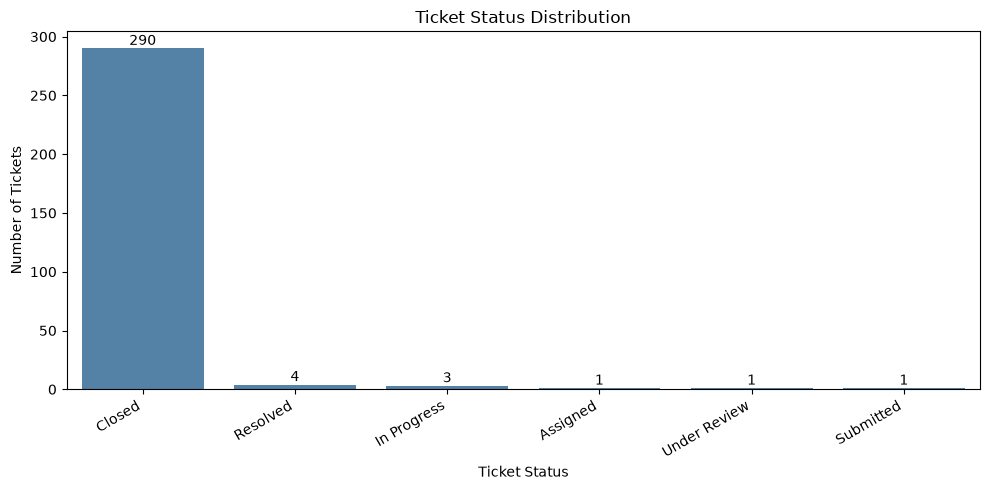

In [9]:
# Ticket Status Distribution

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=status_counts.index,
    y=status_counts.values,
    color="steelblue"
)

# Add ticket counts above bars
for i, count in enumerate(status_counts.values):
    ax.text(i, count + 3, str(count), ha="center")

plt.title("Ticket Status Distribution")
plt.xlabel("Ticket Status")
plt.ylabel("Number of Tickets")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

### 2.7 Ticket Priority Analysis

This section examines the distribution of workplace tickets
across four priority levels: Urgent, High, Medium, and Low.

The analysis aims to:

- Identify the most frequently reported priority levels.
- Calculate ticket counts and percentages by priority.
- Understand the distribution of operational workload.
- Support subsequent SLA performance and statistical analyses.

In [10]:
# Define priority order
priority_order = ["Urgent", "High", "Medium", "Low"]

# Count tickets by priority
priority_counts = (
    df["Priority"]
    .value_counts()
    .reindex(priority_order, fill_value=0)
)

# Calculate percentages
priority_percentages = (
    priority_counts / len(df) * 100
).round(2)

# Create summary table
priority_summary = pd.DataFrame({
    "Ticket Count": priority_counts,
    "Percentage (%)": priority_percentages
})

# Display results
display(priority_summary)

,Ticket Count,Percentage (%)
Priority,,
Urgent,33,11.00
High,113,37.67
Medium,107,35.67
Low,47,15.67


### 2.7.1 Priority Distribution Visualisation

This section visualises the distribution of tickets across
different priority levels.

The chart highlights workload distribution and provides
context for subsequent SLA and resolution performance analyses.

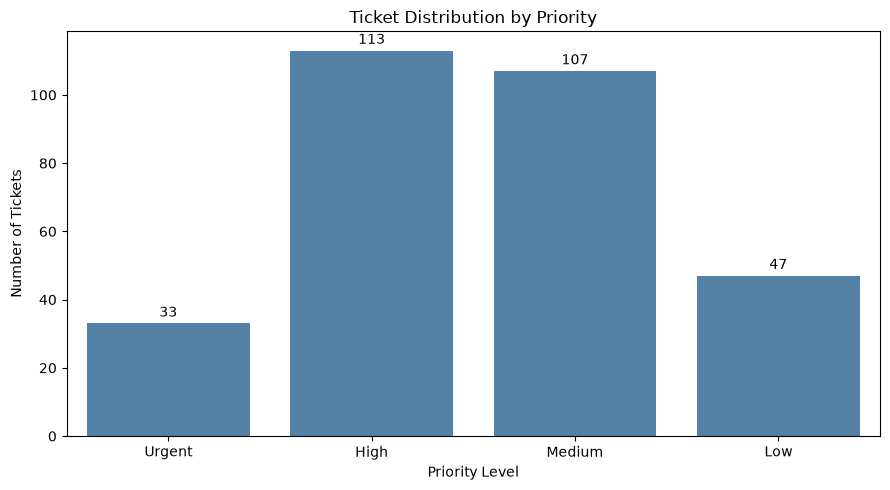

In [11]:
# Visualise ticket distribution by priority

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=priority_counts.index,
    y=priority_counts.values,
    color="steelblue"
)

# Add ticket counts above bars
for i, count in enumerate(priority_counts.values):
    ax.text(i, count + 2, str(count), ha="center")

plt.title("Ticket Distribution by Priority")
plt.xlabel("Priority Level")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

### 2.8 Issue Category Analysis

This section analyses the distribution of workplace issues
across different categories.

The objectives are to:

- Identify the most frequently reported issue categories.
- Calculate ticket counts and percentages by category.
- Understand which types of workplace problems generate
  the highest ticket volumes.
- Support operational planning and Power BI dashboard development.

In [12]:
# Count tickets by category
category_counts = df["Category"].value_counts()

# Calculate category percentages
category_percentages = (
    df["Category"].value_counts(normalize=True) * 100
).round(2)

# Create category summary table
category_summary = pd.DataFrame({
    "Ticket Count": category_counts,
    "Percentage (%)": category_percentages
})

# Display results
display(category_summary)

,Ticket Count,Percentage (%)
Category,,
Facilities,68,22.67
IT Support,45,15.00
Fleet & Vehicles,37,12.33
AV & Meeting Rooms,35,11.67
Cleaning & Hygiene,34,11.33
Estates,30,10.00
Security,28,9.33
Fire & Safety,23,7.67


### 2.8.1 Issue Category Visualisation

This section visualises the distribution of workplace
issues across different categories.

A horizontal bar chart is used to compare ticket volumes
and identify the most frequently reported issue types.

The findings will support operational planning and
Power BI dashboard development.

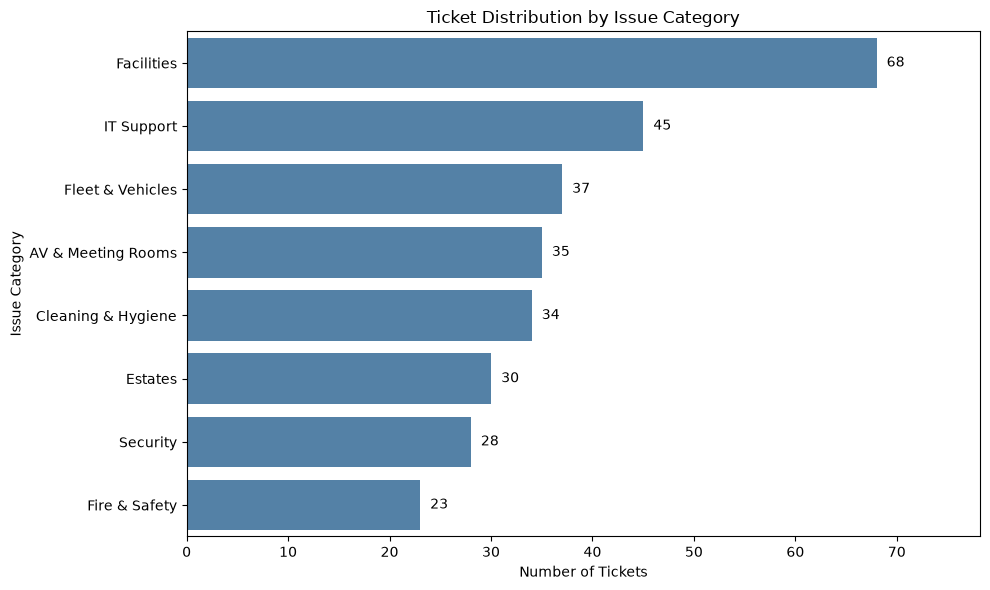

In [13]:
# Visualise ticket distribution by category

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=category_counts.values,
    y=category_counts.index,
    color="steelblue"
)

# Add ticket counts to the bars
for i, count in enumerate(category_counts.values):
    ax.text(count + 1, i, str(count), va="center")

plt.title("Ticket Distribution by Issue Category")
plt.xlabel("Number of Tickets")
plt.ylabel("Issue Category")

plt.xlim(0, category_counts.max() * 1.15)

plt.tight_layout()
plt.show()

### 2.9 SLA Performance Analysis

This section evaluates Service Level Agreement (SLA)
performance for workplace issue tickets.

The analysis focuses on:

- Response SLA compliance
- Resolution SLA compliance
- SLA breaches
- Pending and ongoing tickets

The findings will support operational performance
monitoring, Power BI dashboards, and exploratory
Machine Learning for SLA breach prediction.

In [14]:
# Response SLA distribution
response_sla_counts = df["Response SLA"].value_counts()

# Resolution SLA distribution
resolution_sla_counts = df["Resolution SLA"].value_counts()

# Create summary tables
response_sla_summary = pd.DataFrame({
    "Ticket Count": response_sla_counts,
    "Percentage (%)": (
        response_sla_counts / len(df) * 100
    ).round(2)
})

resolution_sla_summary = pd.DataFrame({
    "Ticket Count": resolution_sla_counts,
    "Percentage (%)": (
        resolution_sla_counts / len(df) * 100
    ).round(2)
})

print("Response SLA Performance:")
display(response_sla_summary)

print("Resolution SLA Performance:")
display(resolution_sla_summary)

Response SLA Performance:


,Ticket Count,Percentage (%)
Response SLA,,
Met,264,88.00
Breached,35,11.67
Pending,1,0.33


Resolution SLA Performance:


,Ticket Count,Percentage (%)
Resolution SLA,,
Met,192,64.0
Breached,102,34.0
Overdue,3,1.0
On Track,3,1.0


### 2.9.1 SLA Compliance and Breach Rate

This section calculates SLA compliance and breach rates
using tickets with a determined SLA outcome.

Pending and On Track tickets are excluded from
compliance calculations.

Overdue tickets are included in the resolution
SLA breach rate.

In [15]:
# Response SLA calculations
response_met = (df["Response SLA"] == "Met").sum()
response_breached = (df["Response SLA"] == "Breached").sum()

response_eligible = response_met + response_breached

response_compliance = (
    response_met / response_eligible * 100
)

response_breach_rate = (
    response_breached / response_eligible * 100
)


# Resolution SLA calculations
resolution_met = (df["Resolution SLA"] == "Met").sum()

resolution_breached = (
    df["Resolution SLA"].isin(["Breached", "Overdue"])
).sum()

resolution_eligible = resolution_met + resolution_breached

resolution_compliance = (
    resolution_met / resolution_eligible * 100
)

resolution_breach_rate = (
    resolution_breached / resolution_eligible * 100
)


# Display results
sla_kpis = pd.DataFrame({
    "KPI": [
        "Response SLA Compliance (%)",
        "Response SLA Breach Rate (%)",
        "Resolution SLA Compliance (%)",
        "Resolution SLA Breach Rate (%)"
    ],
    "Value": [
        round(response_compliance, 2),
        round(response_breach_rate, 2),
        round(resolution_compliance, 2),
        round(resolution_breach_rate, 2)
    ]
})

display(sla_kpis)

,KPI,Value
0,Response SLA Compliance (%),88.29
1,Response SLA Breach Rate (%),11.71
2,Resolution SLA Compliance (%),64.65
3,Resolution SLA Breach Rate (%),35.35


### 2.9.2 Resolution SLA Breaches by Priority

This section examines resolution SLA performance across
different ticket priority levels.

The analysis identifies which priority levels have the
highest number and percentage of SLA breaches.

In [16]:
# Analyse resolution SLA performance by priority

priority_sla = pd.crosstab(
    df["Priority"],
    df["Resolution SLA"]
)

# Ensure expected SLA categories exist
for status in ["Met", "Breached", "Overdue", "On Track"]:
    if status not in priority_sla.columns:
        priority_sla[status] = 0

# Calculate total breaches
priority_sla["Total Breaches"] = (
    priority_sla["Breached"] +
    priority_sla["Overdue"]
)

# Calculate eligible tickets
priority_sla["Eligible Tickets"] = (
    priority_sla["Met"] +
    priority_sla["Total Breaches"]
)

# Calculate breach rate
priority_sla["Breach Rate (%)"] = (
    priority_sla["Total Breaches"] /
    priority_sla["Eligible Tickets"] * 100
).round(2)

# Arrange priority levels
priority_sla = priority_sla.reindex(
    ["Urgent", "High", "Medium", "Low"]
)

display(priority_sla)

Resolution SLA,Breached,Met,On Track,Overdue,Total Breaches,Eligible Tickets,Breach Rate (%)
Priority,,,,,,,
Urgent,11,21,1,0,11,32,34.38
High,50,61,1,1,51,112,45.54
Medium,36,68,1,2,38,106,35.85
Low,5,42,0,0,5,47,10.64


### 2.9.3 Resolution SLA Breach Rate by Priority

This visualisation compares resolution SLA breach rates
across different priority levels.

It helps identify which priority levels are more likely
to exceed their resolution SLA targets.

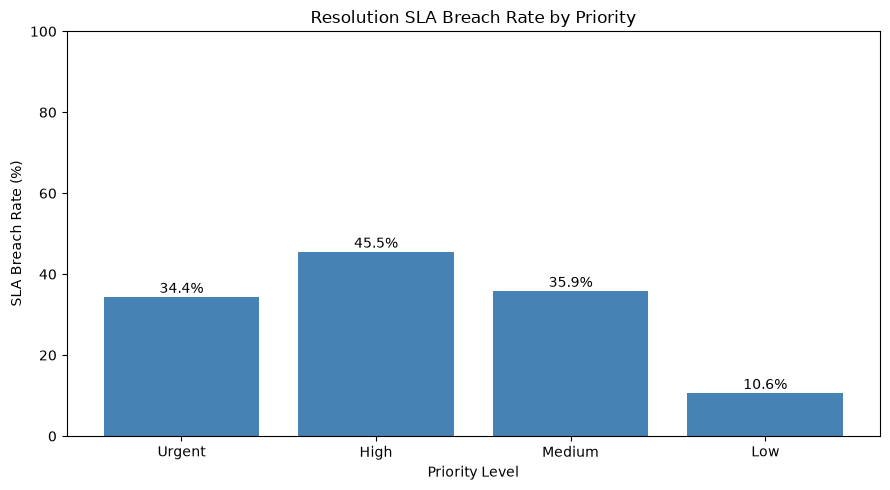

In [17]:
# Visualise resolution SLA breach rate by priority

plt.figure(figsize=(9, 5))

bars = plt.bar(
    priority_sla.index,
    priority_sla["Breach Rate (%)"],
    color="steelblue"
)

# Add percentage labels
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.1f}%",
        ha="center"
    )

plt.title("Resolution SLA Breach Rate by Priority")
plt.xlabel("Priority Level")
plt.ylabel("SLA Breach Rate (%)")

plt.ylim(
    0,
    max(100, priority_sla["Breach Rate (%)"].max() + 10)
)

plt.tight_layout()
plt.show()

### 2.10 Team Performance Analysis

This section evaluates the workload and operational
performance of different support teams.

The analysis focuses on:
- Number of tickets assigned to each team
- Average resolution time by team
- Resolution SLA breach rate by team

These metrics help identify workload differences
and potential areas for service improvement.

#### 2.10.1 Ticket Distribution by Support Team

This analysis examines the number of tickets assigned
to each support team to understand workload distribution.

In [18]:
# Calculate ticket distribution by support team

team_counts = (
    df["Assigned Team"]
    .fillna("Unassigned")
    .value_counts()
)

# Calculate percentages
team_percentages = (
    team_counts / len(df) * 100
).round(2)

# Create summary table
team_summary = pd.DataFrame({
    "Ticket Count": team_counts,
    "Percentage (%)": team_percentages
})

# Display results
display(team_summary)

,Ticket Count,Percentage (%)
Assigned Team,,
Facilities Helpdesk,68,22.67
Fleet Services,37,12.33
AV & Meeting Room Support,35,11.67
Cleaning Services,34,11.33
IT Service Desk,31,10.33
Estates Maintenance,30,10.00
Security & Access Team,28,9.33
Health & Safety Team,23,7.67
IT Network Team,13,4.33


#### 2.10.2 Ticket Distribution by Support Team (Visualisation)

This visualisation compares the number of tickets
assigned to each support team.

It helps identify teams with higher workloads
and provides insights into workload distribution.

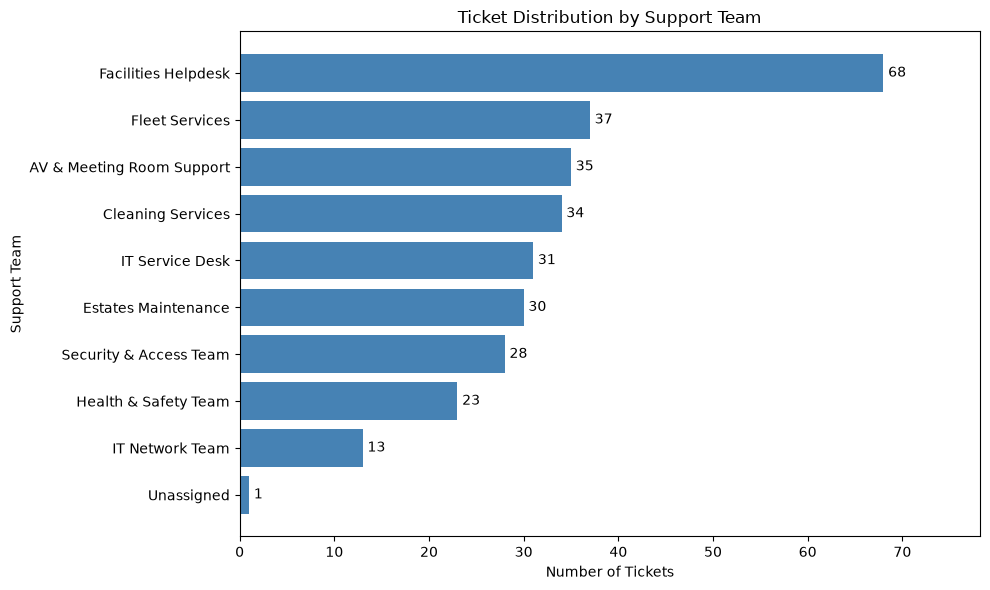

In [19]:
# Visualise ticket distribution by support team

plt.figure(figsize=(10, 6))

bars = plt.barh(
    team_counts.index,
    team_counts.values,
    color="steelblue"
)

# Add ticket count labels
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center"
    )

# Chart formatting
plt.title("Ticket Distribution by Support Team")
plt.xlabel("Number of Tickets")
plt.ylabel("Support Team")

plt.xlim(0, team_counts.max() * 1.15)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

#### 2.10.3 Average Resolution Time by Support Team

This section analyses the average time required to resolve
workplace issues across different support teams.

Only tickets with a recorded resolution time are included.

The analysis helps identify differences in resolution
performance and potential operational bottlenecks.

In [20]:
# Calculate average resolution time by support team

team_resolution = (
    df.groupby("Assigned Team")["Resolution Time (hrs)"]
    .agg(
        Ticket_Count="count",
        Average_Resolution_Time="mean",
        Median_Resolution_Time="median"
    )
    .round(2)
)

# Sort teams by average resolution time
team_resolution = team_resolution.sort_values(
    by="Average_Resolution_Time",
    ascending=False
)

# Display results
display(team_resolution)

,Ticket_Count,Average_Resolution_Time,Median_Resolution_Time
Assigned Team,,,
Facilities Helpdesk,67,77.66,28.80
Estates Maintenance,28,69.31,25.50
IT Service Desk,30,53.32,46.70
Cleaning Services,34,48.41,30.55
Fleet Services,37,45.23,27.40
Security & Access Team,27,42.76,20.20
Health & Safety Team,23,33.43,17.70
AV & Meeting Room Support,35,30.53,23.90
IT Network Team,13,9.50,2.40


#### 2.10.4 Average Resolution Time by Support Team (Visualisation)

This visualisation compares the average resolution time
across different support teams.

The analysis aims to:

- Identify teams with longer average resolution times.
- Compare resolution performance across teams.
- Highlight potential operational bottlenecks.
- Support SLA performance monitoring and Power BI reporting.

Median resolution times should also be considered because
extreme values may influence the averages.

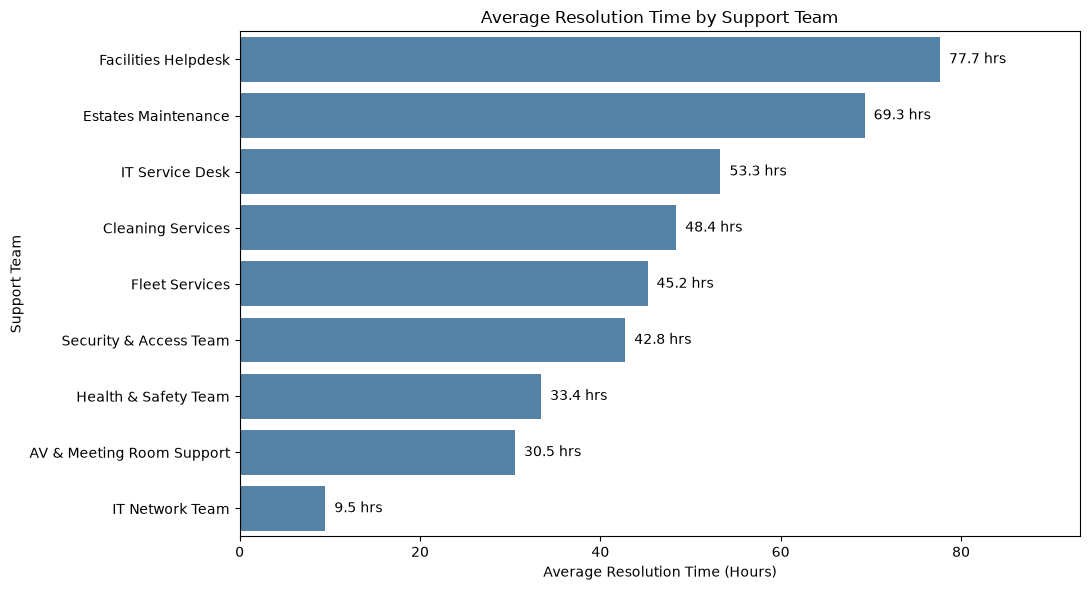

In [21]:
# Visualise average resolution time by support team

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=team_resolution.reset_index(),
    x="Average_Resolution_Time",
    y="Assigned Team",
    color="steelblue"
)

# Add average resolution time labels
for bar in ax.patches:
    width = bar.get_width()

    ax.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f} hrs",
        va="center"
    )

plt.title("Average Resolution Time by Support Team")
plt.xlabel("Average Resolution Time (Hours)")
plt.ylabel("Support Team")

plt.xlim(
    0,
    team_resolution["Average_Resolution_Time"].max() * 1.2
)

plt.tight_layout()
plt.show()

#### 2.10.5 Resolution SLA Breach Rate by Support Team

This analysis evaluates resolution SLA compliance
across different support teams.

The analysis calculates:

- Total eligible tickets per team.
- Number of resolution SLA breaches.
- Resolution SLA breach rate (%).

Both "Breached" and "Overdue" tickets are counted
as SLA breaches, while "On Track" tickets are excluded
from the compliance calculation.

In [22]:
# Calculate resolution SLA performance by support team

team_sla = pd.crosstab(
    df["Assigned Team"].fillna("Unassigned"),
    df["Resolution SLA"]
)

# Ensure all expected SLA statuses exist
for status in ["Met", "Breached", "Overdue", "On Track"]:
    if status not in team_sla.columns:
        team_sla[status] = 0

# Calculate total SLA breaches
team_sla["Total Breaches"] = (
    team_sla["Breached"] +
    team_sla["Overdue"]
)

# Calculate eligible tickets
team_sla["Eligible Tickets"] = (
    team_sla["Met"] +
    team_sla["Total Breaches"]
)

# Calculate SLA breach rate
team_sla["Breach Rate (%)"] = (
    team_sla["Total Breaches"] /
    team_sla["Eligible Tickets"].replace(0, np.nan) * 100
).round(2)

# Sort teams by highest breach rate
team_sla = team_sla.sort_values(
    by="Breach Rate (%)",
    ascending=False
)

# Display results
display(team_sla)

Resolution SLA,Breached,Met,On Track,Overdue,Total Breaches,Eligible Tickets,Breach Rate (%)
Assigned Team,,,,,,,
Cleaning Services,18,16,0,0,18,34,52.94
Security & Access Team,13,14,0,1,14,28,50.00
Facilities Helpdesk,29,38,0,1,30,68,44.12
Estates Maintenance,11,17,1,1,12,29,41.38
Fleet Services,15,22,0,0,15,37,40.54
Health & Safety Team,6,17,0,0,6,23,26.09
AV & Meeting Room Support,7,28,0,0,7,35,20.00
IT Service Desk,3,27,1,0,3,30,10.00
IT Network Team,0,13,0,0,0,13,0.00


#### 2.10.6 Resolution SLA Breach Rate by Support Team (Visualisation)

This visualisation compares resolution SLA breach rates
across different support teams.

The chart helps identify teams with higher breach rates
and highlights potential areas for operational improvement.

Breach rates should be interpreted alongside ticket volumes
and priority levels to ensure meaningful comparisons.

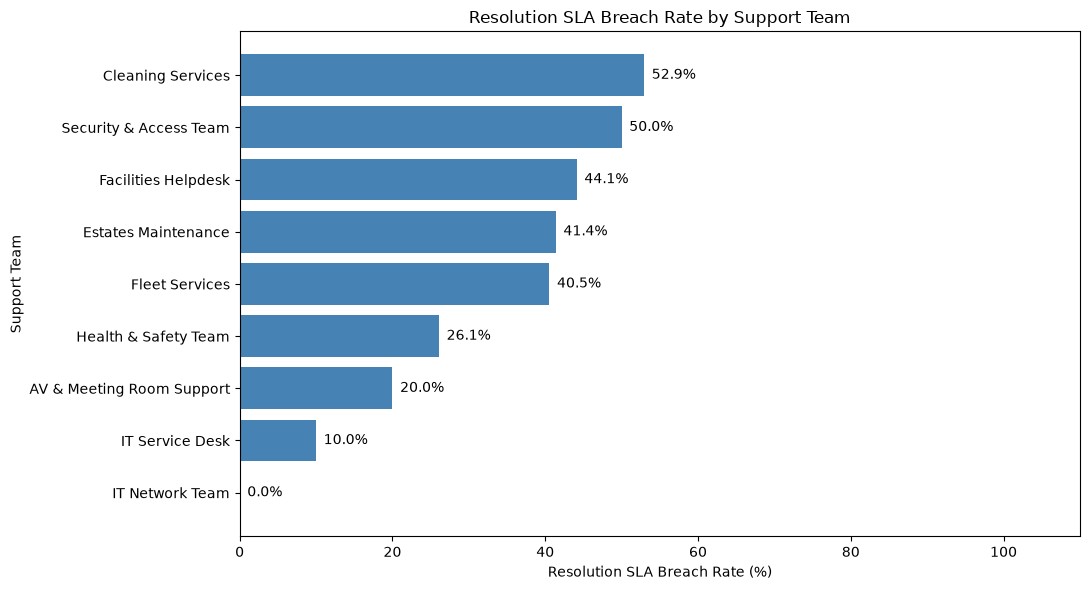

In [23]:
# Visualise resolution SLA breach rate by support team

# Exclude teams without eligible tickets
team_sla_chart = team_sla.dropna(
    subset=["Breach Rate (%)"]
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    team_sla_chart.index,
    team_sla_chart["Breach Rate (%)"],
    color="steelblue"
)

# Add percentage labels
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center"
    )

# Chart formatting
plt.title("Resolution SLA Breach Rate by Support Team")
plt.xlabel("Resolution SLA Breach Rate (%)")
plt.ylabel("Support Team")

plt.xlim(0, 110)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

#### 2.10.7 Team Performance Insights

This section summarises key findings from the support team
performance analysis.

The analysis focuses on three key metrics:

1. Ticket Volume: Number of tickets assigned to each team.
2. Average Resolution Time: Average hours required to resolve tickets.
3. SLA Breach Rate: Percentage of eligible tickets that breached
   their resolution SLA targets.

These metrics provide insights into workload distribution,
resolution efficiency, and SLA compliance.

Teams with higher SLA breach rates may require further
investigation. However, ticket volume, priority levels,
and issue complexity should also be considered before
drawing conclusions about team performance.

In [24]:
# Create final team performance summary

team_performance = pd.DataFrame({
    "Total Tickets": team_counts,
    "Average Resolution Time (hrs)":
        team_resolution["Average_Resolution_Time"],
    "SLA Breach Rate (%)":
        team_sla["Breach Rate (%)"]
})

# Sort by SLA breach rate
team_performance = team_performance.sort_values(
    by="SLA Breach Rate (%)",
    ascending=False
)

# Display summary
display(team_performance.round(2))

,Total Tickets,Average Resolution Time (hrs),SLA Breach Rate (%)
Assigned Team,,,
Cleaning Services,34,48.41,52.94
Security & Access Team,28,42.76,50.00
Facilities Helpdesk,68,77.66,44.12
Estates Maintenance,30,69.31,41.38
Fleet Services,37,45.23,40.54
Health & Safety Team,23,33.43,26.09
AV & Meeting Room Support,35,30.53,20.00
IT Service Desk,31,53.32,10.00
IT Network Team,13,9.50,0.00


## 3. EDA Conclusion

The exploratory data analysis examined ticket volumes,
priority levels, issue categories, response and resolution
times, SLA compliance, and support team performance.

The findings provide a foundation for further statistical
analysis, data modelling, and Power BI dashboard development.

The dataset contains synthetic records; therefore, the
results demonstrate analytical methods rather than
validated real-world operational performance.

## 4. Statistical Analysis & Hypothesis Testing

This section investigates statistical relationships
within the Fix It at Work ticket dataset.

The objectives are to:

1. Test whether resolution time differs across priority levels.
2. Examine differences in resolution time between support teams.
3. Investigate the relationship between priority and SLA breaches.

The dataset is synthetic, so statistical findings are
demonstrative rather than evidence of real-world performance.

In [28]:
%pip install scipy

  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl (36.7 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
from scipy import stats

print("Statistical analysis libraries ready!")

Statistical analysis libraries ready!


In [30]:
# Import statistical testing functions
from scipy import stats

print("Statistical analysis libraries ready!")

Statistical analysis libraries ready!


### 4.1 Hypothesis Test 1: Resolution Time vs Priority

Research Question:
Does resolution time differ significantly across
ticket priority levels?

H0 (Null Hypothesis):
Resolution time distributions are the same
across all priority levels.

H1 (Alternative Hypothesis):
At least one priority level has a different
resolution time distribution.

Significance Level: 0.05

The Kruskal-Wallis test will be used because
resolution times are right-skewed and contain outliers.

In [33]:
# Hypothesis Test 1: Resolution Time vs Priority

from scipy import stats

# Define priority levels
priority_levels = ["Urgent", "High", "Medium", "Low"]

# Prepare resolution time data for each priority
priority_groups = [
    df.loc[
        df["Priority"] == priority,
        "Resolution Time (hrs)"
    ].dropna()
    for priority in priority_levels
]

# Perform Kruskal-Wallis test
h_statistic, p_value = stats.kruskal(*priority_groups)

# Display results
print("Kruskal-Wallis Test Results")
print("--------------------------")
print(f"H-statistic: {h_statistic:.4f}")
print(f"P-value: {p_value:.4f}")

# Interpret results
if p_value < 0.05:
    print("Result: Reject H0")
    print("There is a statistically significant difference.")
else:
    print("Result: Fail to reject H0")
    print("No statistically significant difference was detected.")

Kruskal-Wallis Test Results
--------------------------
H-statistic: 72.5693
P-value: 0.0000
Result: Reject H0
There is a statistically significant difference.


### 4.1.2 Statistical Interpretation

This section interprets the Kruskal-Wallis test results
using a significance level of 0.05.

The analysis determines whether there is sufficient
statistical evidence of differences in resolution time
distributions across ticket priority levels.

In [34]:
# Interpret Kruskal-Wallis test results

alpha = 0.05

print("Hypothesis Test 1: Resolution Time vs Priority")
print("-" * 50)

print(f"P-value: {p_value:.4f}")
print(f"Significance Level: {alpha}")

if p_value < alpha:
    print("\nConclusion:")
    print("Reject the null hypothesis.")
    print(
        "Resolution time distributions differ "
        "significantly across priority levels."
    )
    print(
        "Further pairwise testing is needed to identify "
        "which priority levels differ."
    )
else:
    print("\nConclusion:")
    print("Fail to reject the null hypothesis.")
    print(
        "There is insufficient statistical evidence "
        "of differences across priority levels."
    )

Hypothesis Test 1: Resolution Time vs Priority
--------------------------------------------------
P-value: 0.0000
Significance Level: 0.05

Conclusion:
Reject the null hypothesis.
Resolution time distributions differ significantly across priority levels.
Further pairwise testing is needed to identify which priority levels differ.


### 4.2 Hypothesis Test 2: Resolution Time vs Support Team

**Research Question:**
Does resolution time differ significantly across support teams?

**H0 (Null Hypothesis):**
Resolution time distributions are the same across support teams.

**H1 (Alternative Hypothesis):**
At least one support team has a different resolution time distribution.

**Significance Level:** 0.05

**Statistical Test:** Kruskal-Wallis Test

The Kruskal-Wallis test is used because resolution times
are right-skewed and contain outliers.

In [35]:
# Hypothesis Test 2: Resolution Time vs Support Team

# Prepare resolution time data for each team
team_groups = [
    group["Resolution Time (hrs)"].dropna().values
    for team, group in df.groupby("Assigned Team")
    if group["Resolution Time (hrs)"].notna().sum() >= 2
]

# Perform Kruskal-Wallis test
h_team, p_team = stats.kruskal(*team_groups)

# Display results
print("Kruskal-Wallis Test: Support Teams")
print("-" * 40)

print(f"H-statistic: {h_team:.4f}")
print(f"P-value: {p_team:.4f}")

# Interpret results
if p_team < 0.05:
    print("\nResult: Reject H0")
    print("Resolution time distributions differ significantly between teams.")
else:
    print("\nResult: Fail to reject H0")
    print("No statistically significant difference was detected.")

Kruskal-Wallis Test: Support Teams
----------------------------------------
H-statistic: 32.8438
P-value: 0.0001

Result: Reject H0
Resolution time distributions differ significantly between teams.


### 4.3 Hypothesis Test 3: Priority vs Resolution SLA Breach

**Research Question:**
Is there a statistically significant association between
ticket priority and resolution SLA breaches?

**H0 (Null Hypothesis):**
Ticket priority and resolution SLA breach status are independent.

**H1 (Alternative Hypothesis):**
Ticket priority and resolution SLA breach status are associated.

**Significance Level:** 0.05

**Statistical Test:** Chi-Square Test of Independence

Only tickets with a known SLA outcome are included.
"Breached" and "Overdue" are classified as SLA breaches,
while "Met" is classified as no breach.
"On Track" tickets are excluded.

In [36]:
# Hypothesis Test 3: Priority vs Resolution SLA Breach

# Select tickets with eligible SLA outcomes
sla_data = df[
    df["Resolution SLA"].isin(
        ["Met", "Breached", "Overdue"]
    )
].copy()

# Create binary SLA breach status
sla_data["SLA Breach"] = sla_data["Resolution SLA"].isin(
    ["Breached", "Overdue"]
)

# Create contingency table
contingency_table = pd.crosstab(
    sla_data["Priority"],
    sla_data["SLA Breach"]
)

# Rename columns for readability
contingency_table = contingency_table.rename(
    columns={
        False: "No Breach",
        True: "Breach"
    }
)

# Display contingency table
print("Priority vs Resolution SLA Breach")
display(contingency_table)

# Perform Chi-Square test
chi2, p_chi, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("\nChi-Square Test Results")
print("-" * 35)

print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_chi:.4f}")
print(f"Degrees of Freedom: {dof}")

# Check expected frequencies
print(f"Minimum Expected Frequency: {expected.min():.2f}")

# Interpret results
if p_chi < 0.05:
    print("\nResult: Reject H0")
    print("There is a statistically significant association.")
else:
    print("\nResult: Fail to reject H0")
    print("No statistically significant association was detected.")

if (expected < 5).any():
    print("\nWarning: Some expected frequencies are below 5.")
    print("The Chi-Square approximation may be unreliable.")

Priority vs Resolution SLA Breach


SLA Breach,No Breach,Breach
Priority,,
High,61,51
Low,42,5
Medium,68,38
Urgent,21,11



Chi-Square Test Results
-----------------------------------
Chi-Square Statistic: 17.6672
P-value: 0.0005
Degrees of Freedom: 3
Minimum Expected Frequency: 11.31

Result: Reject H0
There is a statistically significant association.


### 4.4 Statistical Analysis Conclusion

This section summarises the results of three statistical tests:

1. Kruskal-Wallis Test: Resolution Time vs Priority
2. Kruskal-Wallis Test: Resolution Time vs Support Team
3. Chi-Square Test: Priority vs Resolution SLA Breach

The significance level for all tests is 0.05.

The results will help identify statistical differences
and associations within the synthetic ticket dataset.

In [37]:
# Create statistical analysis summary

alpha = 0.05

statistical_summary = pd.DataFrame({
    "Hypothesis Test": [
        "Resolution Time vs Priority",
        "Resolution Time vs Support Team",
        "Priority vs SLA Breach"
    ],

    "Statistical Test": [
        "Kruskal-Wallis",
        "Kruskal-Wallis",
        "Chi-Square"
    ],

    "P-value": [
        p_value,
        p_team,
        p_chi
    ]
})

# Add statistical significance
statistical_summary["Significant"] = (
    statistical_summary["P-value"] < alpha
)

# Add conclusions
statistical_summary["Conclusion"] = np.where(
    statistical_summary["Significant"],
    "Reject H0",
    "Fail to Reject H0"
)

display(statistical_summary.round(4))

,Hypothesis Test,Statistical Test,P-value,Significant,Conclusion
0,Resolution Time vs Priority,Kruskal-Wallis,0.0000,True,Reject H0
1,Resolution Time vs Support Team,Kruskal-Wallis,0.0001,True,Reject H0
2,Priority vs SLA Breach,Chi-Square,0.0005,True,Reject H0


## 5. Final EDA and Statistical Analysis Summary

The exploratory and statistical analyses examined:

- Ticket volumes and status distribution
- Priority and category distribution
- Response and resolution times
- SLA compliance and breach rates
- Support team performance
- Statistical differences in resolution times
- Associations between priority and SLA breaches

These analyses provide a foundation for data modelling,
Power BI dashboard development, and experimental
machine learning.

All findings are based on synthetic data and should
not be interpreted as validated real-world results.